# MMR 다양성 선택

**이 노트북에서 할 일**

1. 07~09절과 같은 방법으로 개발 질문마다 후보 여덟 개를 만듭니다.
2. 질문과의 유사도와 이미 고른 것과의 닮음을 함께 보는 MMR 함수를 만듭니다.
3. 관련성 비중을 1.0·0.5·0.2로 바꿔 고른 목록과 값 세 개를 견줍니다.
4. 보고 자리를 5에서 3으로 줄여 같은 세 줄을 다시 냅니다.

**준비물** — 프로젝트 폴더의 `.env`에 `OPENAI_API_KEY`가 있어야 합니다.
임베딩 요청은 문서 청크 1번과 질문 15번으로 모두 열여섯 번입니다.
예상 비용은 미화 0.01달러 아래이고 답을 쓰는 모델은 부르지 않습니다.
실행 시간은 1분 안팎이고 07·08절과 달리 리랭커는 쓰지 않습니다.

**데이터** — 두 파일 모두 실습 묶음에 들어 있습니다.

- 문서 `labs/part3/ch12-retrieval-tuning/data/advanced-documents.json`(부모 6건·문서 청크 175개)
- 질문 `labs/part3/ch12-retrieval-tuning/data/advanced-queries.json`(30개)

**강의와 실습 범위** — 강의 시간에는 7~9절을 읽습니다.
MMR 함수를 만드는 자리가 7절이고 한 질문에서 고른 목록을 보는 자리가 8절입니다.
9절이 열다섯 질문 평균이고 10절이 값 바꿔 보기입니다.
1~6절은 함께 실행하고 실습 시간에 다시 읽습니다.

**기준 버전** — 첫 셀에서 네 패키지를 고정한 판으로 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

실습 폴더 `labs/part3/ch12-retrieval-tuning`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

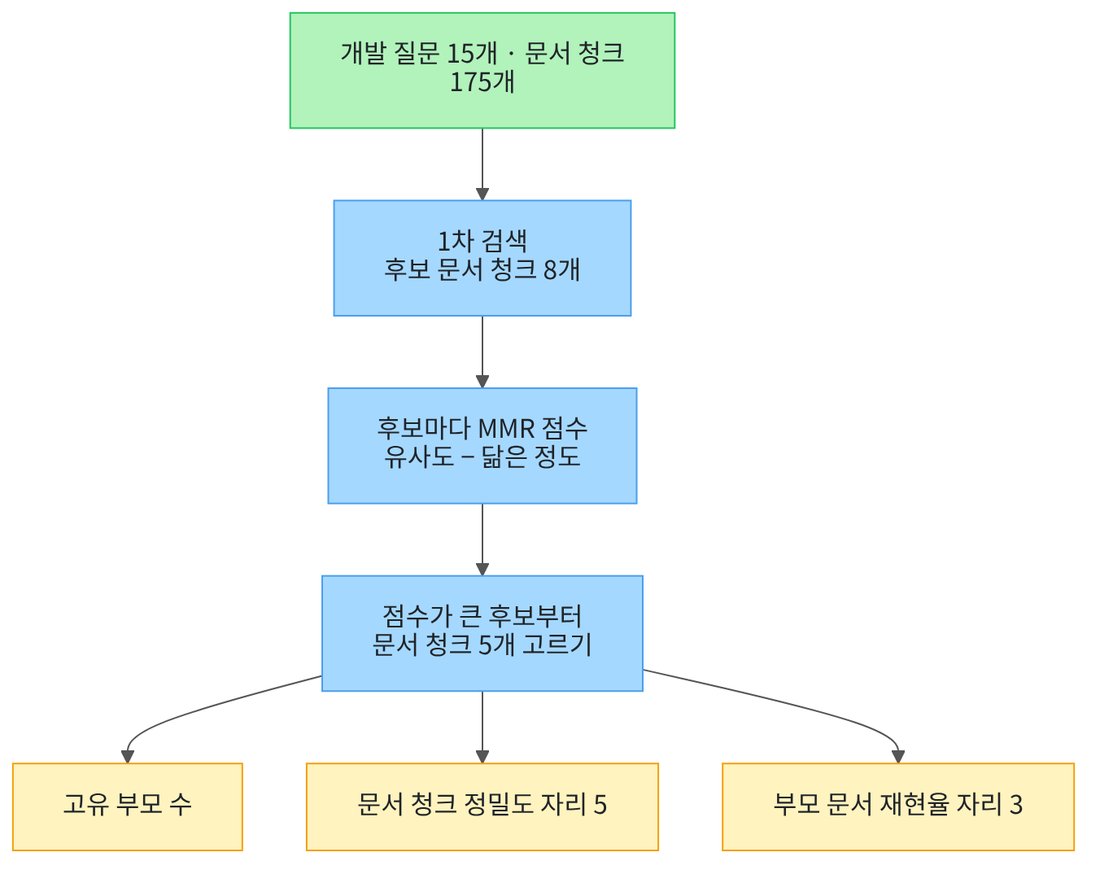

맨 위 초록 상자가 이 절이 쓰는 질문 묶음과 문서 청크 묶음입니다.
그 아래 파란 상자 두 개에서 07~09절과 같은 방법으로 후보 여덟 개를 만듭니다.
가운데 파란 상자가 이 절이 새로 만드는 자리입니다.
후보마다 MMR 점수를 내고 점수가 큰 후보부터 다섯 개를 고릅니다.
맨 아래 노란 상자 세 개가 고른 목록에서 재는 값입니다.

## 1. 준비

첫 셀은 패키지 네 개를 설치하고 설치된 버전을 출력합니다.
09절 다섯 개에서 조각 수를 세는 꾸러미를 뺐습니다. 이 절은 길이를 재지 않습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain-openai==1.6.1" "python-dotenv==1.2.3" "kiwipiepy==0.23.2" "rank-bm25==0.2.2"
from importlib.metadata import version

print("langchain-openai:", version("langchain-openai"))
print("python-dotenv:", version("python-dotenv"))
print("kiwipiepy:", version("kiwipiepy"))
print("rank-bm25:", version("rank-bm25"))

Note: you may need to restart the kernel to use updated packages.
langchain-openai: 1.6.1
python-dotenv: 1.2.3
kiwipiepy: 0.23.2
rank-bm25: 0.2.2


**결과 읽기** — 설치가 끝나면 `langchain-openai: 1.6.1`과 `rank-bm25: 0.2.2`가 보입니다.
네 줄이 모두 보이면 다음 셀로 넘어갑니다.

다음 셀은 이 절에서 쓸 이름 다섯 개를 불러옵니다.

In [2]:
# 자료 읽기·제곱근·형태소 분석·임베딩·낱말 점수에 쓸 이름을 불러옵니다
import json
import math
import os

from kiwipiepy import Kiwi
from langchain_openai import OpenAIEmbeddings
from rank_bm25 import BM25Okapi

print("불러온 이름:", "json", "math", "Kiwi", "OpenAIEmbeddings", "BM25Okapi")

불러온 이름: json math Kiwi OpenAIEmbeddings BM25Okapi


**결과 읽기** — 출력 줄은 `불러온 이름:` 뒤에 이름 다섯 개가 붙은 한 줄입니다.

다음 셀은 API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [3]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


**결과 읽기** — 출력 줄은 `OPENAI_API_KEY 설정 여부: True` 하나입니다.
키 값은 출력하지 않습니다.

다음 셀은 프로젝트 맨 위 폴더를 찾습니다. 01~09절과 같은 코드입니다.

In [4]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part3/ch12-retrieval-tuning/data"):
        root_path = candidate
        break
print("고른 경로:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

고른 경로: .


**결과 읽기** — 출력 줄은 `고른 경로: .`입니다. `assert`도 통과했습니다.

다음 셀은 07~09절과 같은 자료 두 벌을 읽습니다.

In [5]:
# 07~09절과 같은 파일 두 벌을 읽습니다
data_path = root_path + "/labs/part3/ch12-retrieval-tuning/data"
with open(data_path + "/advanced-documents.json", encoding="utf-8") as file:
    documents = json.loads(file.read())
with open(data_path + "/advanced-queries.json", encoding="utf-8") as file:
    queries = json.loads(file.read())
parents = documents["parents"]
chunks = documents["chunks"]
print("부모 문서 수:", len(parents))
print("문서 청크 수:", len(chunks))
print("질문 수:", len(queries))

부모 문서 수: 6
문서 청크 수: 175
질문 수: 30


**결과 읽기** — `부모 문서 수: 6`과 `문서 청크 수: 175`, `질문 수: 30`이 보입니다.
07~09절과 같은 파일이라 세 값도 같습니다.

## 2. 개발 묶음 가리기

Ch 11이 정한 약속은 개발 15문항으로 설정을 고르는 것입니다.
시험 15문항은 설정을 다 고른 뒤 12절에서 한 번만 씁니다.
다음 셀은 답할 수 없는 질문과 정답 ID가 빈 질문을 거르는 08절 함수입니다.

In [6]:
# 답할 수 있고 정답 부모 문서 ID가 있는 질문만 남깁니다(08·09절과 같은 코드)
def eligible_items(subset):
    picked = []
    for item in subset:
        gold_ids = []
        # 같은 정답 ID가 두 번 적혀 있으면 지표의 나누는 수가 달라져 한 번만 둡니다
        for gold_id in item["gold_doc_ids"]:
            if gold_id not in gold_ids:
                gold_ids.append(gold_id)
        item["gold_doc_ids"] = gold_ids
        if item["answerable"] and len(gold_ids) > 0:
            picked.append(item)
    return picked

정의 셀이라 출력이 없습니다. 다음 셀이 그 함수로 개발 묶음을 가립니다.

In [7]:
# 질문 30개에서 개발 묶음만 고르고 답할 수 있는 질문만 남깁니다
dev_all = []
for query in queries:
    if query["split"] == "dev":
        dev_all.append(query)
dev_queries = eligible_items(dev_all)
print("개발 질문 수:", len(dev_queries))
print("시험 질문 수:", len(queries) - len(dev_all))
print("첫 개발 질문:", dev_queries[0]["qid"], "|", dev_queries[0]["question"])
print("그 질문의 정답 부모 문서 ID:", dev_queries[0]["gold_doc_ids"])

개발 질문 수: 15
시험 질문 수: 15
첫 개발 질문: Q001 | 미르시립도서관의 정기 휴관일은 언제인가요?
그 질문의 정답 부모 문서 ID: ['E01']


**결과 읽기** — `개발 질문 수: 15`와 `시험 질문 수: 15`가 보입니다.
줄 `첫 개발 질문:` 뒤에 질문 ID와 질문 글이 있습니다.
정답 칸 값은 `['E01']`처럼 목록이고 값은 부모 문서 ID입니다.

## 3. 이 절에서 쓸 값 정하기

01~09절에서 쓴 값 네 개를 그대로 다시 정합니다.

In [8]:
# 01~09절에서 쓴 값을 그대로 다시 정합니다
similarity_top = 1
keep_tags = ["NNG", "NNP", "NNB", "NR", "VV", "VA", "MAG", "SN", "SL"]
rank_constant = 60
equal_weights = [1.0, 1.0]
print("코사인 유사도의 가장 큰 값:", similarity_top)
print("남길 품사 표시:", keep_tags)
print("순위 상수:", rank_constant)
print("같은 가중치:", equal_weights)

코사인 유사도의 가장 큰 값: 1
남길 품사 표시: ['NNG', 'NNP', 'NNB', 'NR', 'VV', 'VA', 'MAG', 'SN', 'SL']
순위 상수: 60
같은 가중치: [1.0, 1.0]


**결과 읽기** — 줄 `순위 상수: 60`과 `같은 가중치: [1.0, 1.0]`은 06~09절과 같은 값입니다.
줄 `코사인 유사도의 가장 큰 값: 1`은 01절에서 정한 값이고 이 절에서 비중을 나눌 때 다시 씁니다.
라벨 줄 `남길 품사 표시:` 뒤에는 이름 아홉 개가 있습니다.

다음 셀은 이 절에서 견줄 값을 정합니다.
관련성 비중은 MMR 점수에서 질문 관련성이 차지하는 몫입니다.
비중이 1.0이면 닮음을 빼지 않고 0.2이면 닮음 쪽 몫이 0.8이 됩니다.

In [9]:
# 08·09절 후보 수와 두 자리를 잇고 이 절에서 견줄 관련성 비중 세 가지를 더합니다
candidate_count = 8
recall_place = 3
report_place = 5
relevance_weights = [1.0, 0.5, 0.2]
print("후보 수:", candidate_count)
print("부모 문서 재현율을 재는 자리:", recall_place)
print("보고 자리:", report_place)
print("견줄 관련성 비중 세 가지:", relevance_weights)

후보 수: 8
부모 문서 재현율을 재는 자리: 3
보고 자리: 5
견줄 관련성 비중 세 가지: [1.0, 0.5, 0.2]


**결과 읽기** — `후보 수: 8`과 `보고 자리: 5`는 08·09절에서 쓴 값입니다.
라벨 줄 `견줄 관련성 비중 세 가지:` 뒤에 값 `[1.0, 0.5, 0.2]`이 있습니다.
줄 `부모 문서 재현율을 재는 자리: 3`도 08절과 같습니다.

## 4. 검색에 쓸 재료 만들기

문서 청크마다 제목과 본문을 이어 붙여 글 하나로 만듭니다.
청크 ID로 부모 문서 ID를 찾을 수 있게 짝도 함께 만들어 둡니다.

In [10]:
# 문서 청크마다 제목과 본문을 이어 붙이고 청크 ID·부모 문서 ID를 짝지어 둡니다
chunk_texts = []
chunk_ids = []
parent_by_chunk = {}
for chunk in chunks:
    chunk_text = chunk["title"] + " " + chunk["text"]
    chunk_texts.append(chunk_text)
    chunk_ids.append(chunk["chunk_id"])
    parent_by_chunk[chunk["chunk_id"]] = chunk["parent_id"]
all_chunk_count = len(chunk_ids)
print("이어 붙인 글 수:", len(chunk_texts))
print("첫 문서 청크 ID:", chunk_ids[0])

이어 붙인 글 수: 175
첫 문서 청크 ID: E01-P01-C01


**결과 읽기** — `이어 붙인 글 수: 175`가 보입니다.
줄 `첫 문서 청크 ID: E01-P01-C01`의 이름은 부모 ID와 쪽 번호, 문서 청크 번호를 이은 것입니다.
이름 앞머리 `E01`이 그 문서 청크의 부모 문서 ID입니다.

다음 셀은 벡터 쪽 재료를 만듭니다. 01~09절과 같은 모델을 씁니다.
이 절의 고르기는 질문과 후보 사이뿐 아니라 후보끼리도 닮음을 잽니다.
그래서 문서 청크 ID로 벡터를 찾게 해 둡니다.

In [11]:
# 01~09절과 같은 모델로 문서 청크와 개발 질문을 벡터로 바꿉니다(임베딩 요청 16번)
embedding_model_name = "text-embedding-3-small"
vector_dimensions = 256
embedding_model = OpenAIEmbeddings(model=embedding_model_name, dimensions=vector_dimensions)
chunk_vectors = embedding_model.embed_documents(chunk_texts)
query_vectors = []
for query in dev_queries:
    query_vectors.append(embedding_model.embed_query(query["question"]))
vector_by_chunk = {}
# MMR은 후보끼리도 닮음을 재므로 문서 청크 ID로 벡터를 바로 찾게 해 둡니다
for i in range(len(chunk_ids)):
    vector_by_chunk[chunk_ids[i]] = chunk_vectors[i]
print("임베딩 모델 이름:", embedding_model.model)
print("벡터의 숫자 개수 설정:", embedding_model.dimensions)
print("문서 청크 벡터 수:", len(chunk_vectors))
print("질문 벡터 수:", len(query_vectors))

임베딩 모델 이름: text-embedding-3-small
벡터의 숫자 개수 설정: 256
문서 청크 벡터 수: 175
질문 벡터 수: 15


**결과 읽기** — `벡터의 숫자 개수 설정: 256`과 `문서 청크 벡터 수: 175`가 보입니다.
출력 줄 `질문 벡터 수: 15`까지 나오면 임베딩 요청 열여섯 번이 끝났습니다.
이 노트북의 출력은 2026-09-18에 이 모델로 실행한 결과입니다.

## 5. 앞 절에서 만든 함수 다시 만들기

다음 아홉 셀은 01~09절에서 만든 함수 열세 개를 같은 코드로 다시 정의합니다.
셀마다 첫 줄 주석에 어느 절 함수인지 적었습니다.
앞 절에서 이미 읽은 코드라 셀 하나에 함수를 둘이나 셋씩 담았습니다.
모두 정의 셀이라 출력이 없습니다.

In [12]:
# 01절 점곱·길이·코사인 유사도 함수를 같은 코드로 다시 정의합니다
def dot_product(first, second):
    total = 0
    # 반복 번호 i로 두 벡터의 같은 자리 숫자를 짝지어 곱하고 더합니다
    for i in range(len(first)):
        total = total + first[i] * second[i]
    return total


def vector_length(vector):
    squared_sum = dot_product(vector, vector)
    return math.sqrt(squared_sum)


def cosine_similarity(first, second):
    dot = dot_product(first, second)
    length_product = vector_length(first) * vector_length(second)
    return dot / length_product

In [13]:
# 01절 코사인 거리와 04~09절 형태소 고르기를 같은 코드로 다시 정의합니다
def cosine_distance(first, second):
    similarity = cosine_similarity(first, second)
    return similarity_top - similarity


kiwi = Kiwi()


def kiwi_terms(text):
    terms = []
    for token in kiwi.tokenize(text):
        # 조사와 어미는 품사 표시가 목록에 없어 빠집니다
        if token.tag in keep_tags:
            terms.append(token.form)
    return terms

In [14]:
# 05~09절과 같은 코드로 거리가 작은 순서의 순위 목록을 만듭니다
def rank_by_distance(question_vector, top_count):
    pairs = []
    for i in range(len(chunk_ids)):
        distance = cosine_distance(question_vector, chunk_vectors[i])
        pairs.append((distance, chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "거리": round(pair[0], 2)})
    return hit_list[:top_count]

In [15]:
# 05~09절과 같은 코드로 낱말 겹침 점수가 큰 순서의 순위 목록을 만듭니다
def rank_by_bm25(question, top_count):
    question_terms = kiwi_terms(question)
    scores = bm25_model.get_scores(question_terms)
    pairs = []
    for i in range(len(chunk_ids)):
        # 점수에 음수를 붙이면 sorted가 큰 점수를 앞으로 보냅니다
        pairs.append((0 - scores[i], chunk_ids[i]))
    hit_list = []
    for pair in sorted(pairs):
        hit_list.append({"chunk_id": pair[1], "점수": round(0 - pair[0], 2)})
    return hit_list[:top_count]

In [16]:
# 07~09절 문서 청크 ID 모으기와 부모 문서 ID로 바꾸기를 같은 코드로 다시 정의합니다
def unique_chunk_ids(hit_list):
    found_ids = []
    for hit in hit_list:
        if hit["chunk_id"] not in found_ids:
            found_ids.append(hit["chunk_id"])
    return found_ids


def parent_ids_of(found_chunk_ids):
    parent_ids = []
    for chunk_id in found_chunk_ids:
        parent_id = parent_by_chunk[chunk_id]
        # 여러 문서 청크가 같은 부모를 가리키면 처음 나온 자리만 남깁니다
        if parent_id not in parent_ids:
            parent_ids.append(parent_id)
    return parent_ids

In [17]:
# 06~09절과 같은 코드로 순위 목록 여러 개의 자리 몫을 더합니다
def fuse_scores(ranking_list, weight_list):
    scores = {}
    for list_index in range(len(ranking_list)):
        ranking = ranking_list[list_index]
        weight = weight_list[list_index]
        # 자리 번호는 1부터 세고 앞자리일수록 나누는 수가 작아 몫이 큽니다
        for position in range(len(ranking)):
            chunk_id = ranking[position]
            share = weight / (rank_constant + position + 1)
            scores[chunk_id] = scores.get(chunk_id, 0.0) + share
    return scores

In [18]:
# 06~09절과 같은 코드로 합친 점수가 큰 순서의 문서 청크 ID 목록을 만듭니다
def fuse_rank(ranking_list, weight_list):
    scores = fuse_scores(ranking_list, weight_list)
    pairs = []
    for chunk_id in scores:
        pairs.append((0 - scores[chunk_id], chunk_id))
    fused_ids = []
    for pair in sorted(pairs):
        fused_ids.append(pair[1])
    return fused_ids

In [19]:
# Ch 11 02절 재현율과 08·09절 문서 청크 정밀도를 같은 코드로 다시 정의합니다
def recall_at(doc_ids, gold_doc_ids, cutoff):
    top_ids = doc_ids[:cutoff]
    found_count = 0
    for gold_id in gold_doc_ids:
        if gold_id in top_ids:
            found_count = found_count + 1
    return found_count / len(gold_doc_ids)


def chunk_precision_at(found_chunk_ids, gold_doc_ids, cutoff):
    top_ids = found_chunk_ids[:cutoff]
    found_count = 0
    for chunk_id in top_ids:
        if parent_by_chunk[chunk_id] in gold_doc_ids:
            found_count = found_count + 1
    return found_count / cutoff

## 6. 후보 목록 만들기

다음 셀은 문서 청크의 검색 낱말 목록으로 BM25 모델을 만듭니다.

In [20]:
# 문서 청크마다 검색 낱말 목록을 만들고 그 목록으로 BM25 모델을 만듭니다(04~09절과 같은 코드)
kiwi_corpus = []
for text in chunk_texts:
    kiwi_corpus.append(kiwi_terms(text))
bm25_model = BM25Okapi(kiwi_corpus)
print("검색 낱말 목록 수:", len(kiwi_corpus))
print("BM25 모델이 본 문서 청크 수:", bm25_model.corpus_size)
print("문서 청크 하나의 평균 검색 낱말 수:", round(bm25_model.avgdl, 2))

검색 낱말 목록 수: 175
BM25 모델이 본 문서 청크 수: 175
문서 청크 하나의 평균 검색 낱말 수: 44.01


**결과 읽기** — `검색 낱말 목록 수: 175`와 `BM25 모델이 본 문서 청크 수: 175`가 보입니다.
줄 `문서 청크 하나의 평균 검색 낱말 수: 44.01`은 07~09절과 같은 값입니다.

다음 셀은 개발 질문마다 두 순위를 합쳐 앞자리 여덟 개를 후보로 자릅니다.
질문 ID로 질문 벡터도 찾을 수 있게 짝지어 둡니다.

In [21]:
# 개발 질문마다 두 순위를 합쳐 앞자리 여덟 개를 후보로 자릅니다(07~09절과 같은 방법)
candidate_sets = {}
vector_by_query = {}
for query_index in range(len(dev_queries)):
    question_id = dev_queries[query_index]["qid"]
    vector_by_query[question_id] = query_vectors[query_index]
    distance_hits = rank_by_distance(query_vectors[query_index], all_chunk_count)
    score_hits = rank_by_bm25(dev_queries[query_index]["question"], all_chunk_count)
    ranking_list = [unique_chunk_ids(distance_hits), unique_chunk_ids(score_hits)]
    fused_ids = fuse_rank(ranking_list, equal_weights)
    candidate_sets[question_id] = fused_ids[:candidate_count]
print("만든 후보 목록 수:", len(candidate_sets))
print("후보 목록 하나의 문서 청크 수:", len(candidate_sets[dev_queries[0]["qid"]]))

만든 후보 목록 수: 15
후보 목록 하나의 문서 청크 수: 8


**결과 읽기** — `만든 후보 목록 수: 15`와 `후보 목록 하나의 문서 청크 수: 8`이 보입니다.
07~09절과 같은 1차 검색이라 후보 목록도 같은 방법으로 만든 것입니다.

## 7. MMR 점수를 내는 함수 만들기

여기까지가 09절과 같습니다. 이제 후보 여덟 개에서 다섯 개를 고르는 자리를 봅니다.
앞자리부터 다섯 개를 자르면 서로 닮은 문서 청크가 함께 올라올 수 있습니다.
최대 주변 관련성(MMR)은 후보마다 점수를 하나 내고 큰 점수부터 하나씩 고릅니다.
점수는 질문과의 유사도에서 이미 고른 것과 가장 닮은 정도를 뺀 값입니다.

다음 셀은 뺄 쪽을 재는 함수와 점수를 내는 함수를 정의합니다.
닮음을 재는 자는 01절 `cosine_similarity()`를 그대로 씁니다.

In [22]:
# 후보 하나의 닮은 정도와 MMR 점수를 내는 함수 둘을 정의합니다
def similarity_to_chosen(candidate_vectors, chosen, index):
    biggest = 0.0
    for chosen_index in chosen:
        similarity = cosine_similarity(candidate_vectors[index], candidate_vectors[chosen_index])
        if similarity > biggest:
            biggest = similarity
    return biggest


def mmr_score(question_vector, candidate_vectors, chosen, index, relevance_weight):
    # 두 비중을 더하면 1이 되므로 나머지 비중은 빼서 만듭니다
    diversity_weight = similarity_top - relevance_weight
    relevance = cosine_similarity(question_vector, candidate_vectors[index])
    biggest = similarity_to_chosen(candidate_vectors, chosen, index)
    return relevance_weight * relevance - diversity_weight * biggest

정의 셀이라 출력이 없습니다.
첫 함수는 아직 고르지 않은 후보 하나가 이미 고른 것들과 얼마나 닮았는지 잽니다.
가장 닮은 하나의 값만 남기므로 고른 목록에 비슷한 글이 하나만 있어도 점수가 내려갑니다.
아직 아무것도 고르지 않았으면 값은 `0.0`이고 점수는 질문 관련성만으로 정해집니다.

다음 셀은 점수가 가장 큰 자리를 찾는 함수입니다.

In [23]:
# 아직 고르지 않은 후보 가운데 MMR 점수가 가장 큰 자리를 찾습니다
def best_candidate(question_vector, candidate_vectors, chosen, relevance_weight):
    best_index = -1
    best_value = 0.0
    for index in range(len(candidate_vectors)):
        # 이미 고른 자리는 건너뜁니다
        if index not in chosen:
            value = mmr_score(question_vector, candidate_vectors, chosen, index, relevance_weight)
            if best_index == -1 or value > best_value:
                best_index = index
                best_value = value
    return best_index

정의 셀이라 출력이 없습니다.
처음 본 후보를 먼저 가장 좋은 자리로 두고 더 큰 점수가 나오면 바꿉니다.
점수가 음수일 수 있어 `best_index == -1`로 첫 후보를 가립니다.

다음 셀은 고를 수를 채울 때까지 한 자리씩 고르는 함수입니다.

In [24]:
# 고를 수를 채울 때까지 한 자리씩 고르고 고른 자리 번호 목록을 만듭니다
def mmr(question_vector, candidate_vectors, pick_count, relevance_weight):
    chosen = []
    limit = pick_count
    # 후보보다 많이 고를 수는 없습니다
    if len(candidate_vectors) < pick_count:
        limit = len(candidate_vectors)
    while len(chosen) < limit:
        chosen.append(best_candidate(question_vector, candidate_vectors, chosen, relevance_weight))
    return chosen

정의 셀이라 출력이 없습니다.
고른 자리 번호를 목록에 담고 그 목록을 다음 점수 계산에 다시 넘깁니다.
그래서 두 번째 후보부터는 앞에서 고른 것과 닮은 만큼 점수가 깎입니다.

다음 셀은 문서 청크 ID로 넣고 문서 청크 ID로 받는 함수입니다.

In [25]:
# 후보 문서 청크 ID 목록을 넣으면 MMR로 고른 문서 청크 ID 목록이 나옵니다
def mmr_pick(question_vector, found_chunk_ids, place, relevance_weight):
    found_vectors = []
    for chunk_id in found_chunk_ids:
        found_vectors.append(vector_by_chunk[chunk_id])
    chosen = mmr(question_vector, found_vectors, place, relevance_weight)
    picked = []
    for index in chosen:
        picked.append(found_chunk_ids[index])
    return picked

정의 셀이라 출력이 없습니다.
후보 ID 목록을 벡터 목록으로 바꾸고 고른 자리 번호를 다시 ID로 바꿉니다.

## 8. 실행 1 — 한 질문에서 비중 세 가지

먼저 후보가 한 부모 문서에 몰린 질문 하나를 봅니다.
실행 전에 예상해 봅니다. 후보 여덟 개의 부모는 여덟 건보다 적을 것입니다.

In [26]:
# 후보가 한 부모에 몰린 질문 하나를 골라 후보 여덟 개를 봅니다
example_index = 10
example_id = dev_queries[example_index]["qid"]
example_found = candidate_sets[example_id]
example_gold = dev_queries[example_index]["gold_doc_ids"]
print("고른 질문:", example_id, "|", dev_queries[example_index]["question"])
print("그 질문의 정답 부모 문서 ID:", example_gold)
print("후보의 부모 문서 차례:", parent_ids_of(example_found))
print("1차 자리 | 문서 청크 ID | 부모 문서 ID")
for index in range(len(example_found)):
    chunk_id = example_found[index]
    print(index + 1, "|", chunk_id, "|", parent_by_chunk[chunk_id])

고른 질문: Q085 | 누리테크가 납기를 지체하면 지체상금은 얼마이며 한도는?
그 질문의 정답 부모 문서 ID: ['H01']
후보의 부모 문서 차례: ['H01', 'H02', 'M02']
1차 자리 | 문서 청크 ID | 부모 문서 ID
1 | H01-P03-C02 | H01
2 | H01-P03-C03 | H01
3 | H01-P04-C05 | H01
4 | H01-P02-C02 | H01
5 | H01-P02-C06 | H01
6 | H01-P03-C04 | H01
7 | H02-P02-C06 | H02
8 | M02-P06-C01 | M02


**결과 읽기** — 줄 `고른 질문: Q085`는 계약서 문서에서 답을 찾는 질문입니다.
줄 `후보의 부모 문서 차례: ['H01', 'H02', 'M02']`에서 후보의 부모가 세 건임을 알 수 있습니다.
라벨 줄 아래 여덟 줄이 후보 하나씩의 1차 자리와 부모 문서 ID입니다.
맨 오른쪽 칸을 세면 여덟 개 가운데 여섯 개가 `H01`에서 나왔습니다.
정답 부모 문서 ID도 `['H01']`이라 앞자리가 정답 부모로 몰려 있습니다.

다음 셀은 같은 후보에서 관련성 비중만 바꿔 다섯 개를 고릅니다.
실행 전에 예상해 봅니다. 비중을 낮추면 다른 부모의 문서 청크가 들어올 것입니다.

In [27]:
# 같은 후보에서 관련성 비중만 바꿔 문서 청크 다섯 개를 고릅니다
print("관련성 비중 | 고른 문서 청크 ID")
for relevance_weight in relevance_weights:
    example_picked = mmr_pick(vector_by_query[example_id], example_found, report_place, relevance_weight)
    example_parents = parent_ids_of(example_picked)
    example_precision = chunk_precision_at(example_picked, example_gold, report_place)
    print(relevance_weight, "|", example_picked)
    print("  고유 부모 수:", len(example_parents), "| 부모 차례:", example_parents)
    print("  문서 청크 정밀도 자리 5:", round(example_precision, 2))

관련성 비중 | 고른 문서 청크 ID
1.0 | ['H01-P03-C02', 'H01-P04-C05', 'H01-P02-C02', 'H01-P03-C03', 'H01-P03-C04']
  고유 부모 수: 1 | 부모 차례: ['H01']
  문서 청크 정밀도 자리 5: 1.0
0.5 | ['H01-P03-C02', 'H02-P02-C06', 'M02-P06-C01', 'H01-P04-C05', 'H01-P02-C02']
  고유 부모 수: 3 | 부모 차례: ['H01', 'H02', 'M02']
  문서 청크 정밀도 자리 5: 0.6
0.2 | ['H01-P03-C02', 'H02-P02-C06', 'M02-P06-C01', 'H01-P02-C02', 'H01-P04-C05']
  고유 부모 수: 3 | 부모 차례: ['H01', 'H02', 'M02']
  문서 청크 정밀도 자리 5: 0.6


**결과 읽기** — 라벨 줄 아래 비중마다 세 줄씩 나옵니다.
비중 `1.0`에서 고른 다섯 개는 `고유 부모 수: 1`이고 모두 `H01`입니다.
비중 `0.5`와 `0.2`에서는 `고유 부모 수: 3`이 되고 부모 차례에 `H02`와 `M02`가 들어왔습니다.
대신 `문서 청크 정밀도 자리 5:` 값이 `1.0`에서 `0.6`으로 내려갔습니다.
목록이 흩어진 만큼 정답 부모가 아닌 문서 청크도 함께 올라온 것입니다.

## 9. 실행 1 — 열다섯 질문 평균

한 질문에서 본 변화가 열다섯 질문에서도 같은 방향인지 봅니다.
다음 셀은 비중 하나로 열다섯 질문을 모두 고르고 값 세 개의 평균을 내는 함수입니다.

In [28]:
# 비중 하나로 열다섯 질문을 모두 고르고 값 세 개의 질문 평균을 냅니다
def mmr_row(relevance_weight, place):
    parent_total = 0.0
    precision_total = 0.0
    recall_total = 0.0
    for item in dev_queries:
        picked = mmr_pick(vector_by_query[item["qid"]], candidate_sets[item["qid"]], place, relevance_weight)
        parent_ids = parent_ids_of(picked)
        parent_total = parent_total + len(parent_ids)
        precision_total = precision_total + chunk_precision_at(picked, item["gold_doc_ids"], place)
        recall_total = recall_total + recall_at(parent_ids, item["gold_doc_ids"], recall_place)
    parent_mean = round(parent_total / len(dev_queries), 2)
    precision_mean = round(precision_total / len(dev_queries), 2)
    recall_mean = round(recall_total / len(dev_queries), 2)
    return parent_mean, precision_mean, recall_mean

정의 셀이라 출력이 없습니다.
고유 부모 수는 고른 문서 청크의 부모를 중복 없이 센 수입니다.
문서 청크 정밀도와 부모 문서 재현율은 08·09절에서 쓴 함수를 그대로 부릅니다.

다음 셀이 비중 세 가지를 한 표로 냅니다.
실행 전에 예상해 봅니다. 비중이 내려가면 부모 수는 오르고 정밀도는 내려갈 것입니다.

In [29]:
# 관련성 비중 세 가지를 열다섯 질문 평균으로 견줍니다
print("관련성 비중 | 고유 부모 수 평균 | 문서 청크 정밀도 자리 5 | 부모 문서 재현율 자리 3")
for relevance_weight in relevance_weights:
    row = mmr_row(relevance_weight, report_place)
    print(relevance_weight, "|", row[0], "|", row[1], "|", row[2])

관련성 비중 | 고유 부모 수 평균 | 문서 청크 정밀도 자리 5 | 부모 문서 재현율 자리 3
1.0 | 1.73 | 0.81 | 1.0
0.5 | 2.07 | 0.75 | 1.0
0.2 | 2.07 | 0.73 | 1.0


**결과 읽기** — 라벨 줄 아래 세 줄이 나옵니다.
줄 `1.0 | 1.73 | 0.81 | 1.0`이 비중 1.0의 세 값입니다.
비중을 `0.5`로 낮추면 고유 부모 수 평균이 `2.07`로 오르고 정밀도는 `0.75`로 내려갑니다.
비중을 `0.2`로 더 낮춰도 부모 수 평균은 `2.07` 그대로이고 정밀도만 `0.73`이 됩니다.
맨 오른쪽 칸의 부모 문서 재현율은 세 줄 모두 `1.0`이라 이 값으로는 세 비중을 가를 수 없습니다.

## 10. 값 바꿔 보기 — 보고 자리를 3으로

바꿀 값은 보고 자리 하나입니다.
후보 수와 후보 목록, 비중 세 가지는 그대로 둡니다.
실행 전에 예상해 봅니다. 고를 수가 줄어 부모 수도 함께 내려갈 것입니다.

In [30]:
# 값 바꿔 보기: 보고 자리만 3으로 줄이고 같은 질문을 다시 봅니다
report_place = 3
print("관련성 비중 | 고른 문서 청크 ID | 고유 부모 수 | 문서 청크 정밀도 자리 3")
for relevance_weight in relevance_weights:
    small_picked = mmr_pick(vector_by_query[example_id], example_found, report_place, relevance_weight)
    small_parents = parent_ids_of(small_picked)
    small_precision = chunk_precision_at(small_picked, example_gold, report_place)
    print(relevance_weight, "|", small_picked, "|", len(small_parents), "|", round(small_precision, 2))

관련성 비중 | 고른 문서 청크 ID | 고유 부모 수 | 문서 청크 정밀도 자리 3
1.0 | ['H01-P03-C02', 'H01-P04-C05', 'H01-P02-C02'] | 1 | 1.0
0.5 | ['H01-P03-C02', 'H02-P02-C06', 'M02-P06-C01'] | 3 | 0.33
0.2 | ['H01-P03-C02', 'H02-P02-C06', 'M02-P06-C01'] | 3 | 0.33


**결과 읽기** — 라벨 줄 아래 세 줄이 나옵니다.
비중 `1.0`에서 고른 세 개는 모두 `H01`이고 정밀도는 `1.0`입니다.
비중 `0.5`와 `0.2`에서는 세 개가 서로 다른 부모에서 하나씩 나왔습니다.
그 두 줄의 정밀도는 `0.33`입니다.

같은 질문에서 보고 자리 5일 때 정밀도는 0.6이었습니다.
자리 수를 줄이자 같은 비중에서 정밀도가 더 내려갔습니다.

다음 셀은 줄인 보고 자리로 열다섯 질문 평균을 다시 냅니다.

In [31]:
# 줄인 보고 자리로 열다섯 질문 평균 세 줄을 다시 냅니다
print("관련성 비중 | 고유 부모 수 평균 | 문서 청크 정밀도 자리 3 | 부모 문서 재현율 자리 3")
for relevance_weight in relevance_weights:
    row = mmr_row(relevance_weight, report_place)
    print(relevance_weight, "|", row[0], "|", row[1], "|", row[2])

관련성 비중 | 고유 부모 수 평균 | 문서 청크 정밀도 자리 3 | 부모 문서 재현율 자리 3
1.0 | 1.33 | 0.89 | 1.0
0.5 | 1.93 | 0.69 | 1.0
0.2 | 1.93 | 0.67 | 1.0


**결과 읽기** — 줄 `1.0 | 1.33 | 0.89 | 1.0`이 비중 1.0의 세 값입니다.
비중 `0.5`에서 고유 부모 수 평균이 `1.93`으로 오르고 정밀도는 `0.69`로 내려갑니다.
비중 `0.2`에서도 부모 수 평균은 `1.93` 그대로이고 정밀도만 `0.67`이 됩니다.
부모 문서 재현율은 여기서도 세 줄 모두 `1.0`입니다.

9절 표와 견주면 두 값의 차이가 더 커졌습니다.
부모 수 평균은 1.73과 2.07에서 1.33과 1.93으로 벌어졌습니다.
정밀도는 0.81과 0.75에서 0.89와 0.69로 벌어졌습니다.

## 정리

1. 관련성 비중을 낮추면 고른 다섯 개의 고유 부모 수 평균이 1.73에서 2.07로 올랐습니다.
2. 같은 자리에서 문서 청크 정밀도는 0.81에서 0.73으로 내려갔습니다.
3. 부모 문서 재현율은 세 비중 모두 1.0이라 이 조건에서는 가를 수 없었습니다.

11절에서는 대화에서 빠진 대상을 채운 질문으로 다시 검색합니다.